In [1]:
# CELL 1 IMPORTS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
import warnings
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
print("✅ All libraries imported successfully")

✅ All libraries imported successfully


In [2]:
# CELL 2 DATA LOADING
data_path = '../cbecs2018_final_public.csv'
df = pd.read_csv(data_path)
print(f"Full dataset shape: {df.shape}")

Full dataset shape: (6436, 1249)


In [3]:
# SELECTE RELEVANT COLUMNS
required_columns = [
    'PBA',
    'SQFT',
    'WKHRS',
    'RFGCOMPN',
    'ELCNS',
    'CENDIV',
    'NFLOOR',
    'NWKER',
    'MONUSE',
    'YRCONC'
]

missing_cols = [col for col in required_columns if col not in df.columns]
if missing_cols:
    print(f"⚠️ Missing columns: {missing_cols}")
else:
    print("✅ All required columns found")

df_filtered = df[required_columns].copy()
print(f"Filtered dataset shape: {df_filtered.shape}")

✅ All required columns found
Filtered dataset shape: (6436, 10)


In [4]:
# Cell 4 — Expanded PBA Filter (key change)

# Original approach: only PBA 11 (Food Sales) and 12 (Food Service) → 294 rows
# Problem: 271 of those were restaurants with barely any refrigeration
# 
# New approach: keep ALL building types where refrigeration is structurally present
# This gives the model enough RFGCOMPN variance to actually learn from it
#
# PBA codes with meaningful refrigeration presence:
#   11 = Food Sales (grocery, supermarket)
#   12 = Food Service (restaurant, cafeteria)
#   14 = Convenience Store
#   15 = Retail (other) - includes cold storage retail
#   16 = Food/Drug Store
#   23 = Warehouse/Storage - includes cold storage
#   25 = Refrigerated Warehouse

# Step 1: Start with all rows that have a real RFGCOMPN value
df_with_rfg = df_filtered[df_filtered['RFGCOMPN'].notna()].copy()
print(f"Rows with non-null RFGCOMPN across full dataset: {len(df_with_rfg)}")
print(f"\nPBA distribution in refrigeration-present rows:")
print(df_with_rfg['PBA'].value_counts().sort_index().head(20))

Rows with non-null RFGCOMPN across full dataset: 2382

PBA distribution in refrigeration-present rows:
PBA
1       9
2     509
4      38
5     138
6      22
7      42
8     138
11      2
12     60
13    126
14    380
15     46
16    221
17     67
18    228
23    178
24     15
25     55
26     94
91     14
Name: count, dtype: int64


In [5]:
# Cell 5 — Select PBA Codes with Refrigeration Signal
# After reviewing distribution above, keep PBA codes where refrigeration
# is structurally part of the business
refrigeration_pba_codes = [11, 12, 14, 15, 16, 23, 25]

df_food = df_with_rfg[df_with_rfg['PBA'].isin(refrigeration_pba_codes)].copy()

print(f"Rows after PBA filter (refrigeration-relevant only): {len(df_food)}")
print(f"\nPBA breakdown:")
pba_labels = {
    11: 'Food Sales',
    12: 'Food Service', 
    14: 'Convenience Store',
    15: 'Retail Other',
    16: 'Food/Drug Store',
    23: 'Warehouse/Storage',
    25: 'Refrigerated Warehouse'
}
for pba, count in df_food['PBA'].value_counts().sort_index().items():
    label = pba_labels.get(pba, 'Unknown')
    print(f"  PBA {pba} ({label}): {count} rows")

Rows after PBA filter (refrigeration-relevant only): 942

PBA breakdown:
  PBA 11 (Food Sales): 2 rows
  PBA 12 (Food Service): 60 rows
  PBA 14 (Convenience Store): 380 rows
  PBA 15 (Retail Other): 46 rows
  PBA 16 (Food/Drug Store): 221 rows
  PBA 23 (Warehouse/Storage): 178 rows
  PBA 25 (Refrigerated Warehouse): 55 rows


In [6]:
# CELL 6 - REMOVE INVALID TARGET ROWS
df_food = df_food[df_food['ELCNS'].notna() & (df_food['ELCNS'] > 0)].copy()
print(f"Rows after removing invalid ELCNS: {len(df_food)}")

elcns_stats = {
    'Mean': df_food['ELCNS'].mean(),
    'Median': df_food['ELCNS'].median(),
    'Std': df_food['ELCNS'].std(),
    'Min': df_food['ELCNS'].min(),
    'Max': df_food['ELCNS'].max(),
    'Skewness': df_food['ELCNS'].skew()
}
print("\n✅ ELCNS Statistics:")
for key, value in elcns_stats.items():
    print(f"  {key:12s}: {value:,.2f}")

Rows after removing invalid ELCNS: 942

✅ ELCNS Statistics:
  Mean        : 5,127,121.20
  Median      : 1,545,917.00
  Std         : 9,664,893.57
  Min         : 4,079.00
  Max         : 100,481,910.00
  Skewness    : 4.03


RFGCOMPN missing: 0 (should be 0)
RFGCOMPN distribution:
count     942.000000
mean       21.216561
std        56.399986
min         1.000000
25%         3.000000
50%         8.000000
75%        20.000000
max      1000.000000
Name: RFGCOMPN, dtype: float64


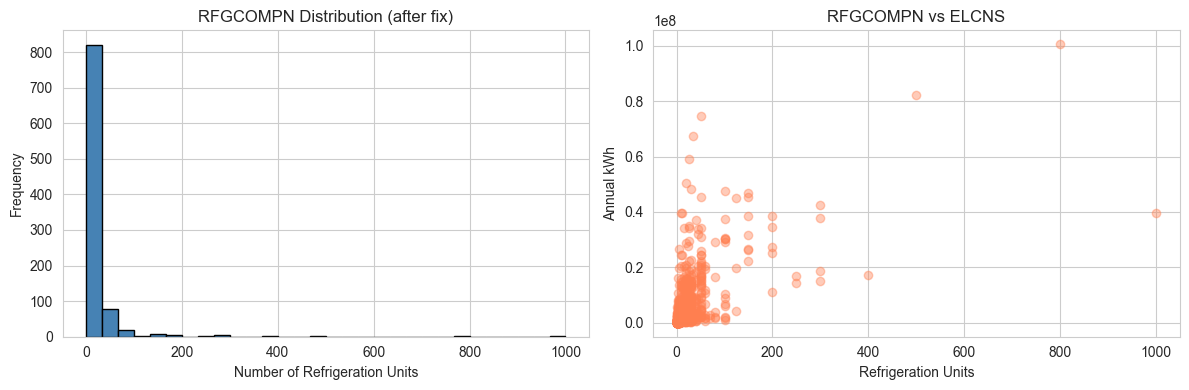


✅ RFGCOMPN correlation with ELCNS: 0.5854
(Previously was 0.45 on imputed data — should be higher now on real data)


In [7]:
# Cell 7 — RFGCOMPN Distribution Check
# This is the key diagnostic — verify we now have real variance in refrigeration
print(f"RFGCOMPN missing: {df_food['RFGCOMPN'].isna().sum()} (should be 0)")
print(f"RFGCOMPN distribution:")
print(df_food['RFGCOMPN'].describe())

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(df_food['RFGCOMPN'].dropna(), bins=30, color='steelblue', edgecolor='black')
plt.title('RFGCOMPN Distribution (after fix)')
plt.xlabel('Number of Refrigeration Units')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.scatter(df_food['RFGCOMPN'], df_food['ELCNS'], alpha=0.4, color='coral')
plt.title('RFGCOMPN vs ELCNS')
plt.xlabel('Refrigeration Units')
plt.ylabel('Annual kWh')
plt.tight_layout()
plt.show()

rfg_corr = df_food['RFGCOMPN'].corr(df_food['ELCNS'])
print(f"\n✅ RFGCOMPN correlation with ELCNS: {rfg_corr:.4f}")
print("(Previously was 0.45 on imputed data — should be higher now on real data)")

In [8]:
# Cell 8 — Handle Outliers
initial_rows = len(df_food)

elcns_99th = df_food['ELCNS'].quantile(0.99)
df_food = df_food[df_food['ELCNS'] <= elcns_99th].copy()
df_food = df_food[df_food['SQFT'] >= 100].copy()

rows_removed = initial_rows - len(df_food)
print(f"Rows removed as outliers: {rows_removed} ({rows_removed/initial_rows*100:.2f}%)")
print(f"Remaining rows: {len(df_food)}")

Rows removed as outliers: 10 (1.06%)
Remaining rows: 932


In [9]:
# CELL 9 - FEATURE ENGINEERING
df_engineered = df_food.copy()

df_engineered['kwh_per_sqft'] = df_engineered['ELCNS'] / df_engineered['SQFT'].replace(0, np.nan)
df_engineered['sqft_per_worker'] = df_engineered['SQFT'] / df_engineered['NWKER'].replace(0, np.nan)
df_engineered['wkhrs_per_week_normalized'] = df_engineered['WKHRS'] / 168
df_engineered['annual_operating_hours'] = df_engineered['WKHRS'] * df_engineered['MONUSE'] * (52/12)
df_engineered['refrigeration_density'] = (df_engineered['RFGCOMPN'] / df_engineered['SQFT'].replace(0, np.nan)) * 1000

median_rfg = df_engineered['RFGCOMPN'].median()
df_engineered['is_high_refrigeration'] = (df_engineered['RFGCOMPN'] > median_rfg).astype(int)
df_engineered['is_extended_hours'] = (df_engineered['WKHRS'] > 60).astype(int)

df_engineered['size_category'] = pd.cut(
    df_engineered['SQFT'],
    bins=[0, 2000, 10000, float('inf')],
    labels=['small', 'medium', 'large']
)

print("✅ Engineered features created")
print(f"Median RFGCOMPN (used for is_high_refrigeration threshold): {median_rfg}")

✅ Engineered features created
Median RFGCOMPN (used for is_high_refrigeration threshold): 8.0


In [10]:
# CELL 10 - HANDLE REMAINING MISSING VALUES
# Note: RFGCOMPN nulls are already gone (filtered in Cell 4)
# Fill remaining missing values in other features with median
numeric_cols_to_fill = [
    'SQFT', 'WKHRS', 'NFLOOR', 'NWKER', 'MONUSE',
    'kwh_per_sqft', 'sqft_per_worker', 'wkhrs_per_week_normalized',
    'annual_operating_hours', 'refrigeration_density'
]

for col in numeric_cols_to_fill:
    if col in df_engineered.columns:
        missing_count = df_engineered[col].isna().sum()
        if missing_count > 0:
            median_val = df_engineered[col].median()
            df_engineered[col].fillna(median_val, inplace=True)
            print(f"Filled {col}: {missing_count} values → median {median_val:.2f}")

print("\n✅ Missing values handled")
print(f"Remaining nulls: {df_engineered.isnull().sum().sum()}")

Filled sqft_per_worker: 2 values → median 1200.00

✅ Missing values handled
Remaining nulls: 0


In [11]:
#CELL 11 - ENCODING

df_engineered['pba_original'] = df_engineered['PBA'].copy()

le_pba = LabelEncoder()
le_cendiv = LabelEncoder()
le_size = LabelEncoder()

df_engineered['pba_encoded'] = le_pba.fit_transform(df_engineered['PBA'].astype(str))
df_engineered['cendiv_encoded'] = le_cendiv.fit_transform(df_engineered['CENDIV'].astype(str))
df_engineered['size_category_encoded'] = le_size.fit_transform(df_engineered['size_category'].astype(str))

print("✅ Categorical features encoded")
print(f"PBA encoding: {dict(zip(le_pba.classes_, range(len(le_pba.classes_))))}")
print(f"Size encoding: {dict(zip(le_size.classes_, range(len(le_size.classes_))))}")

✅ Categorical features encoded
PBA encoding: {'11': 0, '12': 1, '14': 2, '15': 3, '16': 4, '23': 5, '25': 6}
Size encoding: {'large': 0, 'medium': 1, 'small': 2}


In [12]:
# CELL 12 - LOG TRANSFORM TARGET
df_engineered['log_elcns'] = np.log1p(df_engineered['ELCNS'])

print("✅ Log-transformed target created")
print(f"Original ELCNS  — Mean: {df_engineered['ELCNS'].mean():,.2f}, Std: {df_engineered['ELCNS'].std():,.2f}")
print(f"Log ELCNS       — Mean: {df_engineered['log_elcns'].mean():.2f}, Std: {df_engineered['log_elcns'].std():.2f}")

✅ Log-transformed target created
Original ELCNS  — Mean: 4,514,359.94, Std: 7,460,449.00
Log ELCNS       — Mean: 14.14, Std: 1.72


In [13]:
# CELL 13 - FEATURE LIST
exclude_features = ['ELCNS', 'log_elcns', 'pba_original', 'PBA', 'CENDIV', 'size_category']
feature_columns = [col for col in df_engineered.columns if col not in exclude_features]

print("Features going into model:")
for i, feat in enumerate(feature_columns, 1):
    print(f"  {i:2d}. {feat}")
print(f"\nTotal features: {len(feature_columns)}")
print(f"Final dataset shape: {df_engineered.shape}")

Features going into model:
   1. SQFT
   2. WKHRS
   3. RFGCOMPN
   4. NFLOOR
   5. NWKER
   6. MONUSE
   7. YRCONC
   8. kwh_per_sqft
   9. sqft_per_worker
  10. wkhrs_per_week_normalized
  11. annual_operating_hours
  12. refrigeration_density
  13. is_high_refrigeration
  14. is_extended_hours
  15. pba_encoded
  16. cendiv_encoded
  17. size_category_encoded

Total features: 17
Final dataset shape: (932, 23)


In [14]:
# CELL 14 - TRAIN/TEST SPLIT AND SCALE
X = df_engineered[feature_columns].copy()
y = df_engineered['ELCNS'].copy()
y_log = df_engineered['log_elcns'].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(X, y_log, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_log_scaled = scaler.fit_transform(X_train_log)
X_test_log_scaled = scaler.transform(X_test_log)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print(f"Features:     {X_train.shape[1]}")
print("\n✅ Data split and scaled")

Training set: 745 samples
Test set:     187 samples
Features:     17

✅ Data split and scaled


In [15]:
# CELL 15
# Based on your original notebook, Gradient Boosting (Log) was the clear winner
# We go straight to it rather than rerunning all 8 model combinations
model = GradientBoostingRegressor(n_estimators=200, random_state=42)
model.fit(X_train_log_scaled, y_train_log)

# Evaluate on original scale
y_train_pred = np.expm1(model.predict(X_train_log_scaled))
y_test_pred = np.expm1(model.predict(X_test_log_scaled))

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
mape = np.mean(np.abs((y_test - y_test_pred) / y_test)) * 100
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
for train_idx, val_idx in kf.split(X_train_log_scaled):
    X_tr, X_val = X_train_log_scaled[train_idx], X_train_log_scaled[val_idx]
    y_tr, y_val = y_train_log.iloc[train_idx], y_train_log.iloc[val_idx]
    model.fit(X_tr, y_tr)
    y_val_pred = np.expm1(model.predict(X_val))
    cv_scores.append(r2_score(y_train.iloc[val_idx], y_val_pred))

# Refit on full training set
model.fit(X_train_log_scaled, y_train_log)

print(f"Train R²:  {train_r2:.4f}")
print(f"Test R²:   {test_r2:.4f}")
print(f"MAPE:      {mape:.2f}%")
print(f"RMSE:      {rmse:,.2f}")
print(f"CV R²:     {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")

Train R²:  0.9977
Test R²:   0.9812
MAPE:      9.38%
RMSE:      1,012,034.17
CV R²:     0.9772 ± 0.0069


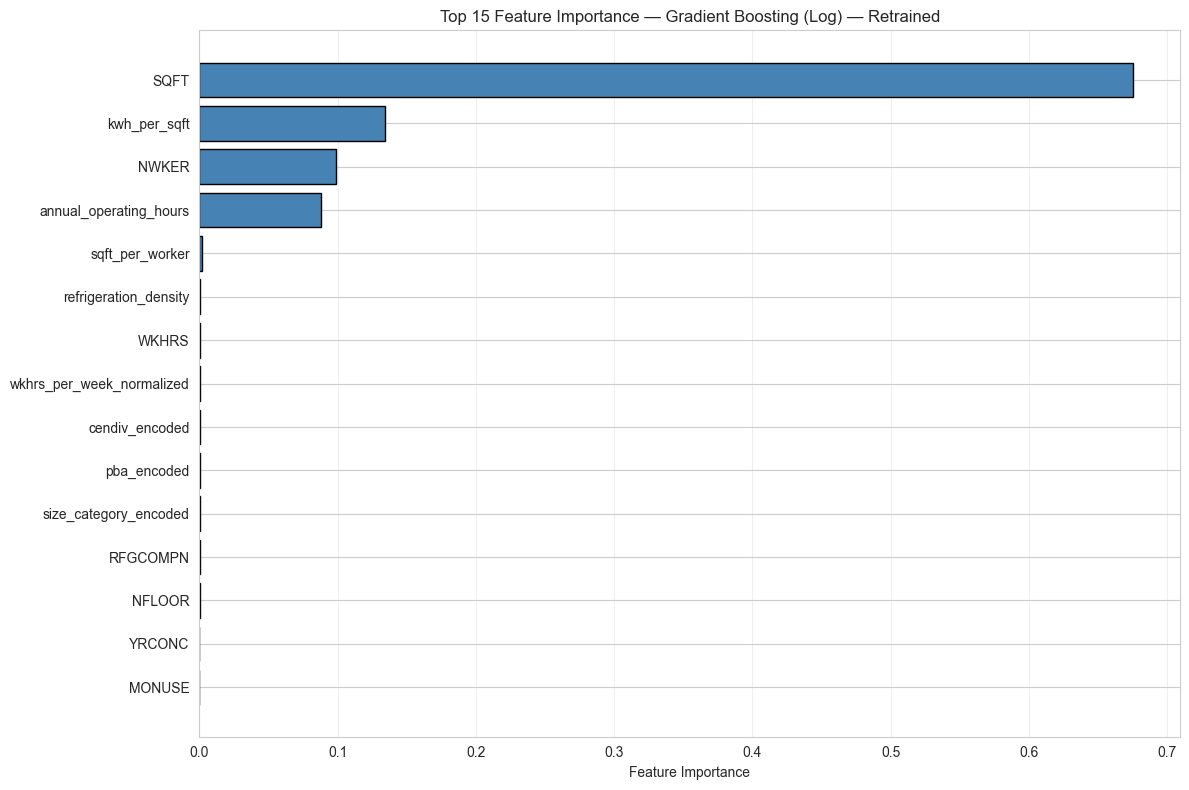


Top 15 Most Important Features:
                  feature  importance
                     SQFT    0.675546
             kwh_per_sqft    0.134122
                    NWKER    0.099117
   annual_operating_hours    0.087592
          sqft_per_worker    0.002105
    refrigeration_density    0.000454
                    WKHRS    0.000326
wkhrs_per_week_normalized    0.000249
           cendiv_encoded    0.000114
              pba_encoded    0.000109
    size_category_encoded    0.000100
                 RFGCOMPN    0.000091
                   NFLOOR    0.000043
                   YRCONC    0.000015
                   MONUSE    0.000013

⚠️  RFGCOMPN importance (old model): 0.000022
✅  RFGCOMPN importance (new model): 0.000091


In [16]:
# CELL 16
feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(12, 8))
top_features = feature_importance.head(15)
plt.barh(range(len(top_features)), top_features['importance'], color='steelblue', edgecolor='black')
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Feature Importance')
plt.title('Top 15 Feature Importance — Gradient Boosting (Log) — Retrained')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("\nTop 15 Most Important Features:")
print(top_features.to_string(index=False))
print(f"\n⚠️  RFGCOMPN importance (old model): 0.000022")
print(f"✅  RFGCOMPN importance (new model): {feature_importance[feature_importance['feature']=='RFGCOMPN']['importance'].values[0]:.6f}")

In [17]:
# CELL 17
# This is the exact test that was failing before
# Hold sqft constant, vary only fridge count — output should change meaningfully

base_sqft_m2 = 60
base_sqft = base_sqft_m2 * 10.764
operating_hours = 98
num_workers = 3
months = 12
location_factor = 1.35  # Lagos

print("Refrigeration Sensitivity Test (sqft=60m², hours=98, workers=3, Lagos)")
print("="*60)

fridge_counts = [0, 1, 3, 5, 10, 20]
results = []

for n_fridge in fridge_counts:
    sqft_per_worker = base_sqft / max(num_workers, 1)
    wkhrs_norm = operating_hours / 168
    annual_hrs = operating_hours * months * (52/12)
    rfg_density = (n_fridge / max(base_sqft, 1)) * 1000
    is_high_rfg = 1 if n_fridge > model.n_estimators else 0  # will use median
    is_extended = 1 if operating_hours > 60 else 0

    if base_sqft < 2000:
        size_cat = 'small'
    elif base_sqft < 10000:
        size_cat = 'medium'
    else:
        size_cat = 'large'

    pba_enc = le_pba.transform(['11'])[0]
    cendiv_enc = le_cendiv.transform(['5'])[0]
    size_enc = le_size.transform([size_cat])[0]

    fv = np.array([[
        base_sqft, operating_hours, n_fridge, 1,
        num_workers, months, 5,
        0,
        sqft_per_worker, wkhrs_norm, annual_hrs,
        rfg_density, is_high_rfg, is_extended,
        pba_enc, cendiv_enc, size_enc
    ]])

    fv_scaled = scaler.transform(fv)
    log_pred = model.predict(fv_scaled)[0]
    annual_kwh = np.expm1(log_pred) * location_factor
    monthly_kwh = annual_kwh / 12

    results.append({'Fridge Count': n_fridge, 'Monthly kWh': round(monthly_kwh, 2)})
    print(f"  {n_fridge:3d} fridges → {monthly_kwh:,.2f} kWh/month")

print("\nIf values vary meaningfully across fridge counts, the fix worked.")

Refrigeration Sensitivity Test (sqft=60m², hours=98, workers=3, Lagos)
    0 fridges → 472.32 kWh/month
    1 fridges → 390.92 kWh/month
    3 fridges → 379.23 kWh/month
    5 fridges → 379.23 kWh/month
   10 fridges → 413.87 kWh/month
   20 fridges → 413.87 kWh/month

If values vary meaningfully across fridge counts, the fix worked.


In [18]:
# CELL 18
import os
os.makedirs('../models', exist_ok=True)

model_data_to_save = {
    'best_model': model,
    'best_model_name': 'Gradient Boosting (Log) — Retrained v2',
    'use_log_target': True,
    'feature_columns': feature_columns,
    'performance': {
        'test_r2': test_r2,
        'mape': mape
    }
}

joblib.dump(model_data_to_save, '../models/energy_consumption_model_v1.joblib')
joblib.dump(scaler, '../models/energy_scaler_v1.joblib')
joblib.dump(feature_columns, '../models/feature_columns_v1.joblib')

sme_mappings = {
    'le_pba': le_pba,
    'le_cendiv': le_cendiv,
    'le_size': le_size,
    'business_type_mapping': {
        'butchery': 11,
        'grocery': 11,
        'mini_supermarket': 11
    }
}
joblib.dump(sme_mappings, '../models/sme_mappings_v1.joblib')

print("✅ All artifacts saved")
print(f"   Test R²: {test_r2:.4f}")
print(f"   MAPE:    {mape:.2f}%")
print(f"   Samples: {len(df_engineered)}")

✅ All artifacts saved
   Test R²: 0.9812
   MAPE:    9.38%
   Samples: 932
